EXTRACCIÓN

In [ ]:
!pip install confluent-kafka

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 15.7 MB/s  0:00:00


In [ ]:
import pandas as pd
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)


In [ ]:
import pandas as pd
from google.colab import userdata
from confluent_kafka import Consumer
import json
import certifi



# Configuración del consumidor para una nueva lectura limpia desde el inicio
conf_analisis = {
    "bootstrap.servers": "kafka-classroom-2026.westus.cloudapp.azure.com:9092",
    "security.protocol": "SASL_SSL",
    "sasl.mechanisms": "SCRAM-SHA-512",
    "sasl.username": "classroom-students",
    "sasl.password": userdata.get("KAFKA_DANIEL"),
    "ssl.ca.location": certifi.where(),
    "group.id": "carlos-fabian-cordoba-1",
    "auto.offset.reset": "earliest"
}

consumer = Consumer(conf_analisis)
consumer.subscribe(['etl.records'])

# Lista para almacenar los registros planos estructurados
eventos_procesados = []

print("Consumiendo y estructurando todos los mensajes históricos...")

try:
    intentos = 0
    while intentos < 10:
        msg = consumer.poll(timeout=1.0)

        if msg is None:
            intentos += 1
            continue

        if msg.error():
            print(f"Error: {msg.error()}")
            continue

        # Decodificar el mensaje
        valor_decodificado = msg.value().decode('utf-8')
        datos = json.loads(valor_decodificado)


        # registro_plano = {
        #     'metadata': {'source_file': '2019.csv', 'year': 2019, 'record_id': '2019-151'},
        #     'data': {'Overall rank': 151,'Country or region': 'Yemen','Score': 3.38,'GDP per capita': 0.287,'Social support': 1.163,'Healthy life expectancy': 0.463,'Freedom to make life choices': 0.143,'Generosity': 0.108,'Perceptions of corruption': 0.077}
        # }

        #  registro_plano = {
        #     'metadata':
        #           {
        #               'source_file':'2019.csv',
        #               'year': 2019,
        #               'record_id':'2019-151'
        #           },
        #     'data':
        #           {
        #               'Overall rank': 151,
        #               'Country or region': 'Yemen',
        #               'Score': 3.38,
        #               'GDP per capita': 0.287,
        #               'Social support': 1.163,
        #               'Healthy life expectancy': 0.463,
        #               'Freedom to make life choices': 0.143,
        #               'Generosity': 0.108,
        #               'Perceptions of corruption': 0.077
        #           }
        #  }



        # Lo siguiente toca hacerlo, pues los datos se encuentran en dos campos anidados:
        # Extraemos los campos del JSON anidado de forma segura
        metadata = datos.get('metadata', {})
        data_fields = datos.get('data', {})


        registro_plano = {
            "source_file": metadata.get("source_file", "N/A"),
            "year": metadata.get("year", None),
            "record_id": metadata.get("record_id", "N/A"),
        }

        for clave, valor in data_fields.items():
            registro_plano[clave] = valor


        # Agregamos a nuestra lista
        eventos_procesados.append(registro_plano)
        intentos = 0  # Reseteamos intentos al recibir datos

    print(f"\n¡Consumo completado! Se han recuperado {len(eventos_procesados)} eventos.")

except KeyboardInterrupt:
    print("\nConsumo detenido manualmente.")
finally:
    consumer.close()

# Convertimos la lista de eventos a un DataFrame de Pandas
df_eventos = pd.DataFrame(eventos_procesados)

# Mostramos las primeras filas de los datos recuperados
display(df_eventos.head(5))

Consumiendo y estructurando todos los mensajes históricos...

¡Consumo completado! Se han recuperado 782 eventos.


,source_file,year,record_id,Country,Region,Happiness Rank,Happiness Score,Standard Error,Economy (GDP per Capita),Family,Health (Life Expectancy),Freedom,Trust (Government Corruption),Generosity,Dystopia Residual,Lower Confidence Interval,Upper Confidence Interval,Happiness.Rank,Happiness.Score,Whisker.high,Whisker.low,Economy..GDP.per.Capita.,Health..Life.Expectancy.,Trust..Government.Corruption.,Dystopia.Residual,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Perceptions of corruption
0,2015.csv,2015,2015-4,Norway,Western Europe,4.0,7.522,0.03880,1.45900,1.33095,0.88521,0.66973,0.36503,0.34699,2.46531,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015.csv,2015,2015-6,Finland,Western Europe,6.0,7.406,0.03140,1.29025,1.31826,0.88911,0.64169,0.41372,0.23351,2.61955,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2015.csv,2015,2015-8,Sweden,Western Europe,8.0,7.364,0.03157,1.33171,1.28907,0.91087,0.65980,0.43844,0.36262,2.37119,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2015.csv,2015,2015-9,New Zealand,Australia and New Zealand,9.0,7.286,0.03371,1.25018,1.31967,0.90837,0.63938,0.42922,0.47501,2.26425,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2015.csv,2015,2015-12,Costa Rica,Latin America and Caribbean,12.0,7.226,0.04454,0.95578,1.23788,0.86027,0.63376,0.10583,0.25497,3.17728,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,2015.csv,2015,2015-15,United States,North America,15.0,7.119,0.03839,1.39451,1.24711,0.86179,0.54604,0.15890,0.40105,2.51011,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,2015.csv,2015,2015-18,Ireland,Western Europe,18.0,6.940,0.03676,1.33596,1.36948,0.89533,0.61777,0.28703,0.45901,1.97570,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,2015.csv,2015,2015-19,Belgium,Western Europe,19.0,6.937,0.03595,1.30782,1.28566,0.89667,0.58450,0.22540,0.22250,2.41484,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,2015.csv,2015,2015-21,United Kingdom,Western Europe,21.0,6.867,0.01866,1.26637,1.28548,0.90943,0.59625,0.32067,0.51912,1.96994,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,2015.csv,2015,2015-24,Singapore,Southeastern Asia,24.0,6.798,0.03780,1.52186,1.02000,1.02525,0.54252,0.49210,0.31105,1.88501,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
!pip install sqlalchemy

In [ ]:
import sqlalchemy
from sqlalchemy import create_engine, URL, text
import pandas as pd
from google.colab import userdata
import warnings
import io
import csv


#credenciales de acceso (yo)
HOST = "aws-0-us-east-1.pooler.supabase.com" #frase
PORT= 6543
PASSWORD = userdata.get('SUPDANEOWN')
DATABASE = "postgres"
USER = "postgres.pnubntjdyhzsfzngmzjk"
DIALECTO = "postgresql+psycopg2"

#url para el motor (yo)
conexion = URL.create(
  drivername=DIALECTO,
  database= DATABASE,
  password= PASSWORD,
  host= HOST,
  port=PORT,
  username=USER
  )

#motor (yo)
engine = create_engine(url=conexion)

#escritura a supabase (yo)
df_eventos.to_sql(
    name="ranking_felicidad",
    con=engine,
    if_exists="replace",
    index=False,
    chunksize=1000
    )



782

FIN DE LA EXTRACCIÓN Y EL GUARDADO

EDA

In [ ]:
# pd.set_option('display.max_rows', None)
# pd.set_option('display.max_columns', None)

Compendio o pipeline de transformaciones. Solo está celda irá al ETL.

In [ ]:
import sqlalchemy
from sqlalchemy import create_engine, URL, text
import pandas as pd
from google.colab import userdata
import warnings
import io


HOST = "aws-0-us-east-1.pooler.supabase.com" #frase
PORT= 6543
PASSWORD = userdata.get('SUPDANEOWN')
DATABASE = "postgres"
USER = "postgres.pnubntjdyhzsfzngmzjk"
DIALECTO = "postgresql+psycopg2"

#url para el motor (yo)
conexion = URL.create(
  drivername=DIALECTO,
  database= DATABASE,
  password= PASSWORD,
  host= HOST,
  port=PORT,
  username=USER
  )

engine= create_engine(url=conexion)

srce_files= ['2015.csv','2016.csv','2017.csv','2018.csv','2019.csv']
dict_pandas_felic={} ########################

for file in srce_files:
  query=text(
    f"""
      SELECT *
      FROM ranking_felicidad
      WHERE source_file='{file}'

    """
    )

  with engine.connect() as conn:
    resultado=pd.read_sql(query, con=conn)
    dict_pandas_felic[file]=resultado


clmns_arc2015_2016= """record_id, year, Country, Happiness Score, Happiness Rank, Economy (GDP per Capita), Health (Life Expectancy), Freedom, Family, Trust (Government Corruption), Generosity"""
clmns_arc2017="""record_id, year, Country, Happiness.Score, Happiness.Rank, Economy..GDP.per.Capita., Health..Life.Expectancy., Freedom, Family, Trust..Government.Corruption., Generosity"""
clmns_arc2018_2019="""record_id, year, Country or region, Score, Overall rank, GDP per capita, Healthy life expectancy, Freedom to make life choices, Social support, Perceptions of corruption, Generosity"""

clmns={
    "clmns_arc2015_2016": clmns_arc2015_2016,
    "clmns_arc2017": clmns_arc2017,
    "clmns_arc2018_2019": clmns_arc2018_2019
    }

list_clmns = {}
for clave, valor in clmns.items():
  lista_clm= valor.split(",")
  limp_espac = [elemento.strip() for elemento in lista_clm]
  list_clmns[clave]=limp_espac

dict_trbjo={}
dict_trbjo["2015.csv"]=(dict_pandas_felic['2015.csv'])[list_clmns["clmns_arc2015_2016"]]
dict_trbjo["2016.csv"]=(dict_pandas_felic['2016.csv'])[list_clmns["clmns_arc2015_2016"]]
dict_trbjo["2017.csv"]=(dict_pandas_felic['2017.csv'])[list_clmns["clmns_arc2017"]]
dict_trbjo["2018.csv"]=(dict_pandas_felic['2018.csv'])[list_clmns["clmns_arc2018_2019"]]
dict_trbjo["2019.csv"]=(dict_pandas_felic['2019.csv'])[list_clmns["clmns_arc2018_2019"]]

#unificación de nombres entre tablas
columnas_estandar = [
    'record_id', 'year', 'country',
    'happiness_score', 'happiness_rank', 'gdp_per_capita',
    'health_life_expectancy', 'freedom', 'family_or_social_support',
    'trust_government_corruption',
    'generosity'
]

df_2015 = dict_trbjo['2015.csv'].copy()
df_2016 = dict_trbjo['2016.csv'].copy()
df_2017 = dict_trbjo['2017.csv'].copy()
df_2018 = dict_trbjo['2018.csv'].copy()
df_2019 = dict_trbjo['2019.csv'].copy()

#todos tienen exactamente 10 columnas ordenadas de la misma forma)
df_2015.columns = columnas_estandar
df_2016.columns = columnas_estandar
df_2017.columns = columnas_estandar
df_2018.columns = columnas_estandar
df_2019.columns = columnas_estandar

#Concatenación
feliz_union = pd.concat([df_2015, df_2016, df_2017, df_2018, df_2019], ignore_index=True)

#limpieza __
feliz_union['country'] = feliz_union['country'].str.strip() #quitar espacios
feliz_union.drop_duplicates(subset=['country', 'year'], keep='first', inplace=True) #quitar duplicados
feliz_union.reset_index(drop=True, inplace=True) #reestablecer el índice

#resolución de nombres equivalentes entre países
equivalencias = {
    'Hong Kong S.A.R., China': 'Hong Kong',
    'Macedonia': 'North Macedonia',
    'Northern Cyprus': 'North Cyprus',
    'Somaliland region': 'Somaliland Region',
    'Taiwan Province of China': 'Taiwan',
    'Trinidad & Tobago': 'Trinidad and Tobago',
}

feliz_modelo = feliz_union.copy()
feliz_modelo['country'] = feliz_modelo['country'].str.strip().replace(equivalencias)
feliz_modelo['trust_government_corruption'].fillna(feliz_modelo['trust_government_corruption'].median(), inplace=True)





#n_dup = feliz_modelo.duplicated(subset=['country', 'year']).sum()

# if n_dup: #se supone que, de no haber duplicados, daría cero y se reinterpretaría como Falso, omitiendo la línea de código que continua
#     print(f"Advertencia: {n_dup} duplicados país-año tras normalizar nombres; se conserva el primero.")
#     feliz_modelo = feliz_modelo.drop_duplicates(subset=['country', 'year'], keep='first')


Observación

In [ ]:
# Instalar ydata-profiling y forzar una versión compatible de numpy para evitar el conflicto con Numba
!pip install -q -U ydata-profiling "numpy<2.2"

# Es posible que necesites reiniciar el entorno de ejecución (Runtime -> Restart session) si el error persiste después de ejecutar esta celda.
from ydata_profiling import ProfileReport

profile = ProfileReport(feliz_union, title="Reporte de felicidad", explorative=True)

# Mostrar el reporte dentro del notebook
profile.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 11/11 [00:00<00:00, 31.64it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Hay un valor nulo en confianza en las instituciones y corrupción

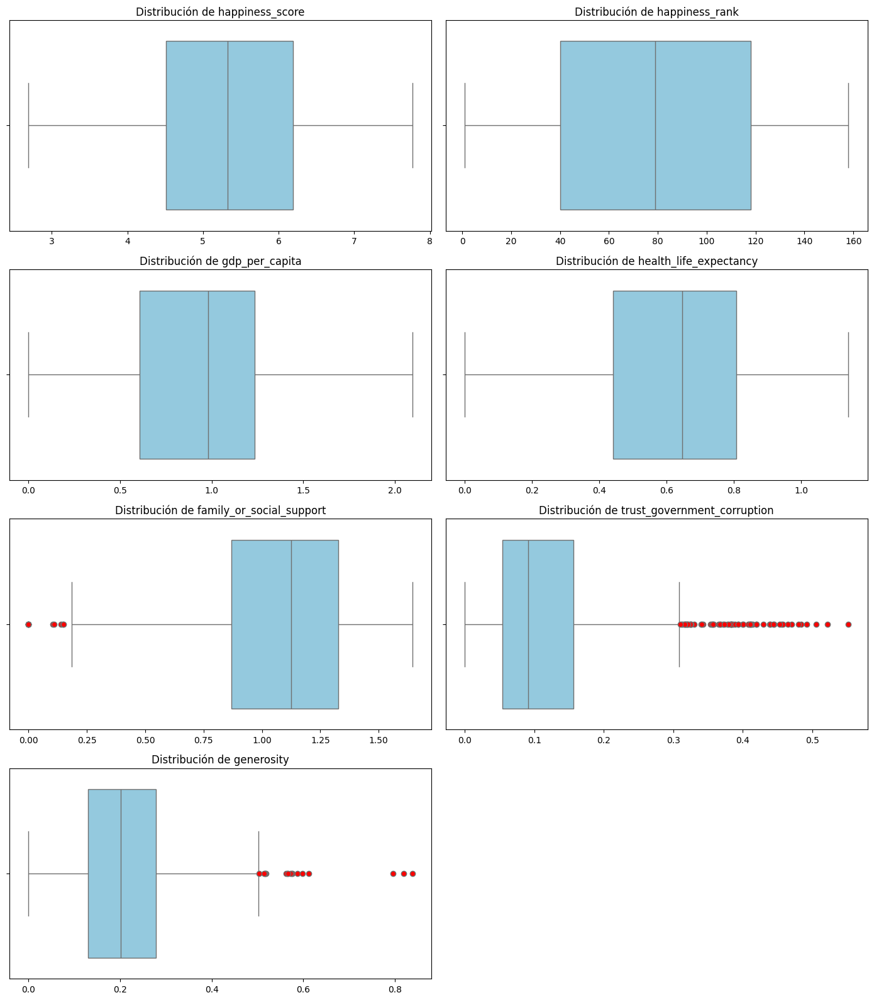

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Seleccionamos las columnas numéricas que queremos graficar
# Excluimos 'year' y 'record_id' ya que no representan magnitudes continuas de interés para boxplots individuales
columnas_numericas = feliz_union.select_dtypes(include=['float64', 'int64']).columns
columnas_a_graficar = [col for col in columnas_numericas if col not in ['year', 'record_id']]

# 2. Configuramos el tamaño de la figura en cuadrículas según el número de variables
num_columnas = len(columnas_a_graficar)
fig, axes = plt.subplots(nrows=(num_columnas + 1) // 2, ncols=2, figsize=(14, 4 * ((num_columnas + 1) // 2)))
axes = axes.flatten() # Aplanamos la matriz de ejes para iterar fácilmente

# 3. Generamos un diagrama de caja para cada variable numérica
for i, col in enumerate(columnas_a_graficar):
    sns.boxplot(data=feliz_union, x=col, ax=axes[i], color='skyblue', flierprops=dict(markerfacecolor='red', marker='o'))
    axes[i].set_title(f'Distribución de {col}', fontsize=12)
    axes[i].set_xlabel('')

# 4. Eliminamos los subplots sobrantes si el número de variables es impar
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

,count,mean,std,min,25%,50%,75%,max
happiness_score,782.0,5.379,1.127,2.693,4.510,5.322,6.190,7.769
gdp_per_capita,782.0,0.916,0.407,0.000,0.606,0.982,1.236,2.096
family_or_social_support,782.0,1.078,0.330,0.000,0.869,1.125,1.327,1.644
health_life_expectancy,782.0,0.612,0.248,0.000,0.440,0.647,0.808,1.141
freedom,782.0,0.411,0.153,0.000,0.310,0.431,0.531,0.724
trust_government_corruption,781.0,0.125,0.106,0.000,0.054,0.091,0.156,0.552
generosity,782.0,0.219,0.122,0.000,0.130,0.202,0.279,0.838




Promedio de determinada caracterísitica por año:




,happiness_score,gdp_per_capita,family_or_social_support,health_life_expectancy,freedom,trust_government_corruption,generosity
year,,,,,,,
2015,5.376,0.846,0.991,0.630,0.429,0.143,0.237
2016,5.382,0.954,0.794,0.558,0.371,0.138,0.243
2017,5.354,0.985,1.189,0.551,0.409,0.123,0.247
2018,5.376,0.891,1.213,0.597,0.455,0.112,0.181
2019,5.407,0.905,1.209,0.725,0.393,0.111,0.185




Distribuciones característica por año:




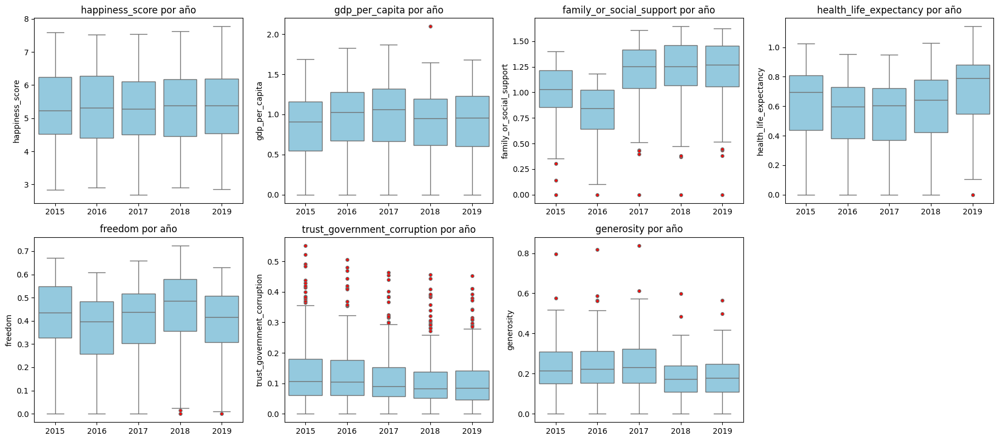

In [ ]:
variables_comparables = [
                          'happiness_score',
                          'gdp_per_capita',
                          'family_or_social_support',
                          'health_life_expectancy',
                          'freedom',
                          'trust_government_corruption',
                          'generosity'
                        ]



# Estadísticas descriptivas generales
display(feliz_modelo[variables_comparables].describe().round(3).T) #transpuesta (..comodidad, pues)


######################################################################################
# Promedio por año: permite ver si las variables cambian de escala entre archivos
print("\n")
print("Promedio de determinada caracterísitica por año:")
print("\n")
display(feliz_modelo.groupby('year')[variables_comparables].mean().round(3))



######################################################################################
# Boxplot por año: comprobación visual de la integración
print("\n")
print("Distribuciones característica por año:")
print("\n")
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, var in zip(axes.flatten(), variables_comparables):
    sns.boxplot(data=feliz_modelo, x='year', y=var, ax=ax, color='skyblue',
                flierprops=dict(markerfacecolor='red', marker='o', markersize=4))
    ax.set_title(f'{var} por año')
    ax.set_xlabel('')
fig.delaxes(axes.flatten()[-1])
plt.tight_layout()
plt.show()

In [31]:
#Nombres de países que no aparecen en los 5 años (posibles variantes del mismo nombre)
anios_por_pais = feliz_union.groupby('country')['year'].nunique()

incompletos = anios_por_pais[anios_por_pais < 5].sort_values()

print(f"\nPaíses que no aparecen en los 5 años: {len(incompletos)}")

display(
    feliz_union[feliz_union['country'].isin(incompletos.index)]
    .groupby('country')['year'].apply(lambda s: sorted(s.unique())).to_frame('años')
)

print("\n---------------------------------------------------------------------------")
print("\n                            ATIPICOS")
print("\n-------------------------------------------------------------------------")

# Valores atípicos por método IQR (se marcan; no se eliminan)
variables_numericas = [
                        'happiness_score',
                        'gdp_per_capita',
                        'family_or_social_support',
                        'health_life_expectancy',
                        'trust_government_corruption',
                        'generosity'
                       ]

filas_atipicos = []
for vari in variables_numericas:

    q1, q3 = feliz_union[vari].quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = (q1 - 1.5 * iqr), (q3 + 1.5 * iqr)

    n_atipicos = int(((feliz_union[vari] < lim_inf) | (feliz_union[vari] > lim_sup)).sum())

    filas_atipicos.append({
        'variable': vari,
        'minimo': feliz_union[vari].min(),
        'maximo': feliz_union[vari].max(),
        'limite_inferior': lim_inf,
        'limite_superior': lim_sup,
        'atipicos': n_atipicos,
    })
print("\n")
print("\nDistribución respecto a los cuantiles 2do y 3ro. cantidad de atípicos fuera de los límites")
print("\n")
display(pd.DataFrame(filas_atipicos).round(3))


Países que no aparecen en los 5 años: 29


,años
country,
Angola,"[2015, 2016, 2017, 2018]"
Belize,"[2016, 2017, 2018]"
Central African Republic,"[2015, 2017, 2018, 2019]"
Comoros,"[2015, 2016, 2019]"
Djibouti,[2015]
Gambia,[2019]
Hong Kong,"[2015, 2016, 2018, 2019]"
"Hong Kong S.A.R., China",[2017]
Laos,"[2015, 2016, 2018, 2019]"



---------------------------------------------------------------------------

                            ATIPICOS

-------------------------------------------------------------------------



Distribución respecto a los cuantiles 2do y 3ro. cantidad de atípicos fuera de los límites




,variable,minimo,maximo,limite_inferior,limite_superior,atipicos
0,happiness_score,2.693,7.769,1.990,8.709,0
1,gdp_per_capita,0.000,2.096,-0.338,2.181,0
2,family_or_social_support,0.000,1.644,0.183,2.014,10
3,health_life_expectancy,0.000,1.141,-0.112,1.360,0
4,trust_government_corruption,0.000,0.552,-0.099,0.309,67
5,generosity,0.000,0.838,-0.093,0.502,17


### Resumen de hallazgos del EDA

- **Cobertura:** 782 registros (158, 157, 155, 156 y 156 países por año, de 2015 a 2019). Tras la limpieza el panel tiene 782 filas sin duplicados país-año.
- **Calidad:** hay **un único valor faltante** (`Perceptions of corruption`, 2018, United Arab Emirates), que se imputa con la mediana dentro del pipeline. Los rangos de todas las variables son válidos y no hay valores fuera de dominio.
- **Relación con el score:** el PIB per cápita (r ≈ 0.79), la esperanza de vida saludable (r ≈ 0.74), el apoyo social (r ≈ 0.65) y la libertad (r ≈ 0.55) son los predictores más fuertes. La percepción de corrupción tiene una relación moderada (r ≈ 0.40) y la generosidad es la más débil (r ≈ 0.14). Este patrón coincide con lo que documenta el World Happiness Report.
- **Multicolinealidad:** los VIF están entre 1.2 y 3.0, muy por debajo de 5, así que las seis variables pueden usarse juntas sin redundancia grave.
- **Atípicos (IQR):** `Perceptions of corruption` tiene 67 valores altos y `Generosity` 17; el apoyo social tiene 10. Se conservan porque son valores reales de países con percepciones de corrupción o donaciones extremas, no errores.
- **Problemas de datos detectados y tratados:**
  - La unificación original ya incluye `Freedom` (columna `Libertad`), así que el panel tiene las seis variables completas.
  - Seis variantes de nombre entre años (por ejemplo, `Macedonia` y `North Macedonia`) se normalizaron con un diccionario de equivalencias.
  - 29 países no aparecen en los cinco años. Es un hecho de la cobertura del reporte, no un error, así que se conservan.
- **Selección de features:** se excluyen el ranking y `Dystopia Residual` (derivados del score, es decir, leakage) y las variables de incertidumbre. Los predictores finales son las seis variables de la sección anterior.

### Valores faltantes, atípicos y formatos inconsistentes

La observación inicial (*sin valores nulos ni duplicados*) se verifica aquí con código. Además se revisan espacios sobrantes, nombres de países y rangos válidos.

Los valores atípicos se **marcan pero no se eliminan**: en este dataset son valores reales de países con situaciones extremas, no errores de captura. Solo se corregirían valores que estén fuera del dominio de la variable (por ejemplo, un score negativo).

### 1. Exploración de los registros por año

In [ ]:
resumen = []
for archivo, df_raw in dict_pandas_felic.items():
    col_pais = [c for c in df_raw.columns if c.startswith('Country')][0]
    resumen.append({
        'archivo': archivo,
        'filas': len(df_raw),
        'columnas': df_raw.shape[1],
        'paises_unicos': df_raw[col_pais].nunique(),
        'valores_nulos': int(df_raw.isna().sum().sum()),
    })
display(pd.DataFrame(resumen))

for archivo, df_raw in dict_pandas_felic.items():
    print(f"{archivo}: {list(df_raw.columns)}")

,archivo,filas,columnas,paises_unicos,valores_nulos
0,2015.csv,158,33,158,2844
1,2016.csv,157,33,157,2669
2,2017.csv,155,33,155,2790
3,2018.csv,156,33,0,3277
4,2019.csv,156,33,0,3276


2015.csv: ['source_file', 'year', 'record_id', 'Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Standard Error', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual', 'Lower Confidence Interval', 'Upper Confidence Interval', 'Happiness.Rank', 'Happiness.Score', 'Whisker.high', 'Whisker.low', 'Economy..GDP.per.Capita.', 'Health..Life.Expectancy.', 'Trust..Government.Corruption.', 'Dystopia.Residual', 'Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Perceptions of corruption']
2016.csv: ['source_file', 'year', 'record_id', 'Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Standard Error', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual', 'Lower Confidence Interval', 'Upper Confidence Interval', 

### 2. Columnas comunes y únicas entre archivos

La matriz muestra en qué años aparece cada columna. Los nombres cambian entre archivos (`Happiness Score` → `Happiness.Score` → `Score`, `Family` → `Social support` desde 2018, `Freedom` → `Freedom to make life choices`), por eso la unificación de la sección EDA se hizo **por posición** y no por nombre.

In [ ]:
todas_las_columnas = sorted(set().union(*[set(df.columns) for df in dict_pandas_felic.values()]))

presencia = pd.DataFrame(
    {archivo: [c in df.columns for c in todas_las_columnas] for archivo, df in dict_pandas_felic.items()},
    index=todas_las_columnas
)
display(presencia)

columnas_comunes = presencia.index[presencia.all(axis=1)].tolist()
columnas_no_comunes = presencia.index[~presencia.all(axis=1)].tolist()
print("Columnas presentes en los 5 archivos:", columnas_comunes)
print("Columnas que no están en todos los archivos:", columnas_no_comunes)

# Columnas que la unión de 10 variables no utiliza (incluye 'Freedom', que quedó fuera)
usadas = set(list_clmns["clmns_arc2015_2016"]) | set(list_clmns["clmns_arc2017"]) | set(list_clmns["clmns_arc2018_2019"])
no_usadas = [c for c in todas_las_columnas if c not in usadas and c not in ('source_file', 'year', 'record_id')]
print("\nColumnas disponibles que la unión inicial no utilizó:", no_usadas)

,2015.csv,2016.csv,2017.csv,2018.csv,2019.csv
Country,True,True,True,True,True
Country or region,True,True,True,True,True
Dystopia Residual,True,True,True,True,True
Dystopia.Residual,True,True,True,True,True
Economy (GDP per Capita),True,True,True,True,True
Economy..GDP.per.Capita.,True,True,True,True,True
Family,True,True,True,True,True
Freedom,True,True,True,True,True
Freedom to make life choices,True,True,True,True,True
GDP per capita,True,True,True,True,True


Columnas presentes en los 5 archivos: ['Country', 'Country or region', 'Dystopia Residual', 'Dystopia.Residual', 'Economy (GDP per Capita)', 'Economy..GDP.per.Capita.', 'Family', 'Freedom', 'Freedom to make life choices', 'GDP per capita', 'Generosity', 'Happiness Rank', 'Happiness Score', 'Happiness.Rank', 'Happiness.Score', 'Health (Life Expectancy)', 'Health..Life.Expectancy.', 'Healthy life expectancy', 'Lower Confidence Interval', 'Overall rank', 'Perceptions of corruption', 'Region', 'Score', 'Social support', 'Standard Error', 'Trust (Government Corruption)', 'Trust..Government.Corruption.', 'Upper Confidence Interval', 'Whisker.high', 'Whisker.low', 'record_id', 'source_file', 'year']
Columnas que no están en todos los archivos: []

Columnas disponibles que la unión inicial no utilizó: ['Dystopia Residual', 'Dystopia.Residual', 'Lower Confidence Interval', 'Region', 'Standard Error', 'Upper Confidence Interval', 'Whisker.high', 'Whisker.low']


Transformaciones

In [ ]:
# Diccionario de equivalencias de nombres de países.
# Variantes detectadas en los datos reales (felicidad.xlsx): mismo país con nombre distinto entre años.
equivalencias = {
    'Hong Kong S.A.R., China': 'Hong Kong',
    'Macedonia': 'North Macedonia',
    'Northern Cyprus': 'North Cyprus',
    'Somaliland region': 'Somaliland Region',
    'Taiwan Province of China': 'Taiwan',
    'Trinidad & Tobago': 'Trinidad and Tobago',
}

# 'Freedom' ya viene incluida en la unificación de la celda original (columna 'Libertad' -> 'freedom').
feliz_modelo = feliz_union.copy()

# 3) Limpieza de formato
feliz_modelo['country'] = feliz_modelo['country'].str.strip().replace(equivalencias)

n_dup = feliz_modelo.duplicated(subset=['country', 'year']).sum()

if n_dup: #se supone que, de no haber duplicados, daría cero y se reinterpretaría como Falso, omitiendo la línea de código que continua
    print(f"Advertencia: {n_dup} duplicados país-año tras normalizar nombres; se conserva el primero.")
    feliz_modelo = feliz_modelo.drop_duplicates(subset=['country', 'year'], keep='first')

### 4. Decisión de integración de los años

**Decisión:** apilar los cinco archivos en un único panel *país-año* (formato largo), con nombres de columna estandarizados y la columna `year` como identificador temporal.

**Justificación:**
- Cada fila representa un país en un año, que es la unidad de análisis del problema.
- Un único modelo aprende relaciones que se mantienen en el tiempo, y `year` permite estudiar la evolución.
- Las variables comparten significado (score en escala 0–10 y componentes de contribución). El boxplot por año de la celda siguiente permite verificar que los rangos son consistentes entre archivos.

**Limitaciones:**
- Las definiciones cambian entre años: `Family` y `Social support` no son exactamente la misma medida, y la percepción de corrupción depende de encuestas que cambian.
- La cobertura de países no es constante, con países que entran o salen de un año a otro.
- Un mismo país aparece hasta cinco veces, así que las observaciones no son independientes. Por eso la validación aleatoria puede ser optimista (ver evaluación).
- `Region` y `Dystopia Residual` no existen en todos los años y no se usan como predictores.
- La unificación por posición depende de que el orden de las columnas sea el mismo en cada archivo; la verificación de rangos ayuda a detectar un desfase.

### 5. Estadísticas descriptivas y visualizaciones

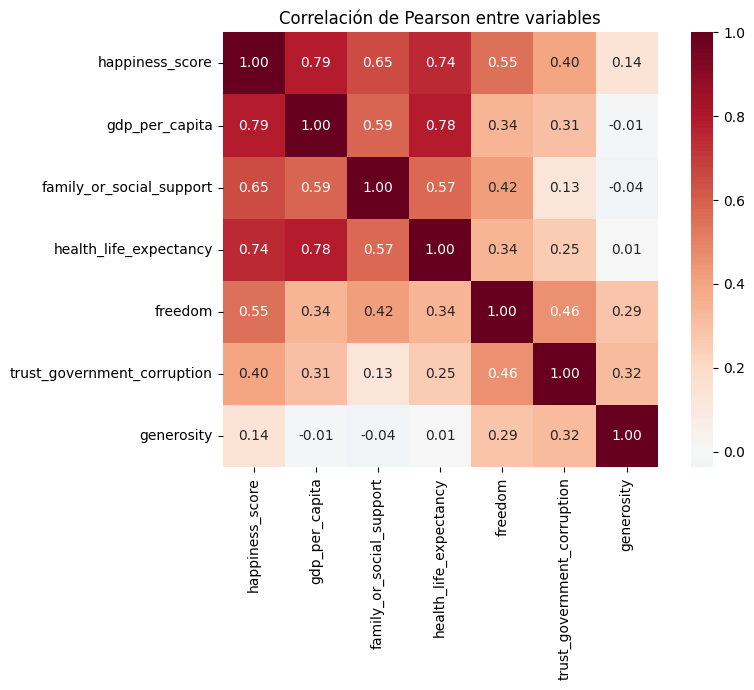

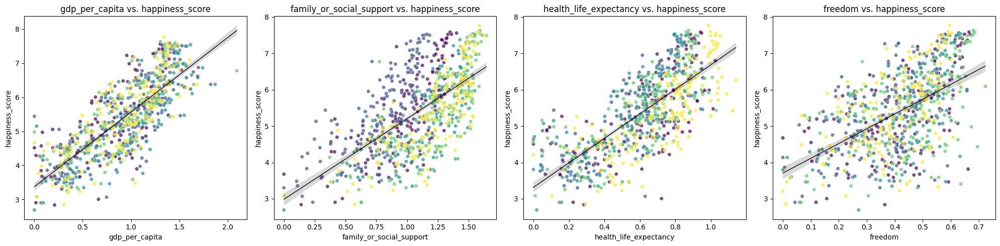

In [ ]:
# Matriz de correlación entre variables
plt.figure(figsize=(9, 7))
sns.heatmap(feliz_modelo[variables_comparables].corr(), annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, square=True)
plt.title('Correlación de Pearson entre variables')
plt.tight_layout()
plt.show()

# Relación de cada variable clave con el score, coloreada por año
pares = ['gdp_per_capita', 'family_or_social_support', 'health_life_expectancy', 'freedom']
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, var in zip(axes, pares):
    sns.scatterplot(data=feliz_modelo, x=var, y='happiness_score', hue='year',
                    palette='viridis', alpha=0.7, s=28, legend=False, ax=ax)
    sns.regplot(data=feliz_modelo, x=var, y='happiness_score', scatter=False,
                color='black', line_kws={'lw': 1}, ax=ax)
    ax.set_title(f'{var} vs. happiness_score')
plt.tight_layout()
plt.show()

### Selección de características relevantes

Se usan como predictores las variables de contexto de cada país que, según la correlación con el score, se relacionan con él: PIB per cápita, apoyo social, esperanza de vida saludable, libertad, percepción de corrupción y generosidad.

**Variables excluidas y motivo:**
- `Happiness Rank` / `Overall rank`: es la posición derivada del propio score; usarla sería *data leakage*.
- `Dystopia Residual`: se calcula a partir del score, por lo que también filtraría la respuesta.
- `Standard Error`, intervalos de confianza y `Whisker`: describen la incertidumbre del score, no son información disponible para predecirlo.
- `Region`: no existe en los archivos de 2017 a 2019.
- `year`: se usa solo para la validación temporal; incluirla como predictor mezclaría el efecto del tiempo con el de las variables.

In [32]:
from sklearn.linear_model import LinearRegression

objetivo = 'happiness_score'
candidatas = ['gdp_per_capita', 'family_or_social_support', 'health_life_expectancy',
              'freedom', 'trust_government_corruption', 'generosity']

# Correlación de cada candidata con el score
corr_objetivo = feliz_modelo[candidatas + [objetivo]].corr()[objetivo].drop(objetivo)
print("Correlación de Pearson con happiness_score:")
display(corr_objetivo.sort_values(ascending=False).round(3).to_frame('r'))

# Multicolinealidad: VIF = 1 / (1 - R²) de cada predictor frente a los demás
vif = {}
base_vif = feliz_modelo[candidatas].dropna()   # VIF requiere filas completas (1 fila con trust faltante)
for c in candidatas:
    otras = [o for o in candidatas if o != c]
    r2_c = LinearRegression().fit(base_vif[otras], base_vif[c]).score(base_vif[otras], base_vif[c])
    vif[c] = 1 / (1 - r2_c)
print("\nVIF (valores altos, por encima de 5-10, indican redundancia):")
display(pd.Series(vif, name='VIF').round(2).to_frame())

Correlación de Pearson con happiness_score:


,r
gdp_per_capita,0.789
health_life_expectancy,0.742
family_or_social_support,0.649
freedom,0.551
trust_government_corruption,0.398
generosity,0.138



VIF (valores altos, por encima de 5-10, indican redundancia):


,VIF
gdp_per_capita,3.00
family_or_social_support,1.83
health_life_expectancy,2.77
freedom,1.61
trust_government_corruption,1.44
generosity,1.19


## Entrenamiento del modelo

Sigue la misma estructura de `ml_basico.ipynb`, aplicada al panel de felicidad. Requiere haber ejecutado las celdas anteriores, en particular la que construye `feliz_modelo`.

In [33]:
import numpy as np
from sklearn.model_selection import train_test_split, GroupKFold, cross_val_score
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
TARGET = 'happiness_score'
FEATURES = ['gdp_per_capita', 'family_or_social_support', 'health_life_expectancy',
            'freedom', 'trust_government_corruption', 'generosity']

print("Target:", TARGET)
print("Predictores:", FEATURES)

Target: happiness_score
Predictores: ['gdp_per_capita', 'family_or_social_support', 'health_life_expectancy', 'freedom', 'trust_government_corruption', 'generosity']


### 1. Variable objetivo y predictores

- **Target:** `happiness_score`.
- **Predictores:** las seis variables seleccionadas en el EDA. Todas son numéricas, así que no requieren codificación.

### 2. Separación entre entrenamiento y prueba

Se usa 80 % para entrenamiento y 20 % para prueba, con `random_state=42`, igual que en el notebook base. Esta separación es aleatoria por filas, así que un mismo país puede aparecer en ambos conjuntos. Esa limitación se aborda en la evaluación.

In [34]:
X = feliz_modelo[FEATURES]
y = feliz_modelo[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print("Registros de entrenamiento:", X_train.shape[0])
print("Registros de prueba:", X_test.shape[0])

Registros de entrenamiento: 625
Registros de prueba: 157


### 3. Modelo base: regresión lineal

La regresión lineal es el punto de partida: es interpretable (cada coeficiente indica el efecto de una variable) y sirve como referencia. Se compara con Random Forest, que puede capturar relaciones no lineales. El workshop permite considerar otros algoritmos siempre que se justifique la elección.

### 4. Estrategia de preprocesamiento sin fuga de información

El preprocesamiento va dentro de un `Pipeline`, igual que en el ejemplo:

1. `SimpleImputer` con mediana: la mediana se calcula solo con `X_train`.
2. `StandardScaler`: la media y la desviación estándar se aprenden solo con `X_train`.

Al llamar a `fit` con los datos de entrenamiento, las estadísticas del conjunto de prueba no influyen en el modelo. El panel limpio no tiene valores faltantes, pero el imputador queda como protección para nuevos datos que lleguen desde Kafka.

In [40]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]),
            FEATURES
        )
    ]
)

modelo_lineal = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

# El entrenamiento ocurre aquí.
modelo_lineal.fit(X_train, y_train)
print("Regresión lineal entrenada")

lr = modelo_lineal.named_steps["model"]
print("\nCoeficientes (por cada desviación estándar del predictor):")
for feat, coef in zip(FEATURES, lr.coef_):
    print(f"- {feat}: {coef:.4f}")
print(f"- Intercepto: {lr.intercept_:.4f}")

Regresión lineal entrenada

Coeficientes (por cada desviación estándar del predictor):
- gdp_per_capita: 0.4875
- family_or_social_support: 0.2121
- health_life_expectancy: 0.2425
- freedom: 0.2078
- trust_government_corruption: 0.0854
- generosity: 0.0796
- Intercepto: 5.3905


In [41]:
# Modelo alternativo con el mismo preprocesamiento
modelo_rf = Pipeline(steps=[
    ("preprocessing", clone(preprocessor)),
    ("model", RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                    random_state=RANDOM_STATE))
])

modelo_rf.fit(X_train, y_train)
print("Random Forest entrenado")

Random Forest entrenado


## Evaluación y reporte

### 1. Predicciones frente a datos reales de prueba


Usamos `X_test`, que los modelos no vieron durante el entrenamiento. Se compara cada predicción con el valor real `y_test`, y se identifica el país y el año de cada registro.

In [42]:
y_pred = modelo_lineal.predict(X_test)
y_pred_rf = modelo_rf.predict(X_test)

comparacion = feliz_modelo.loc[X_test.index, ['country', 'year']].copy()
comparacion['real'] = y_test.values
comparacion['prediccion_lineal'] = y_pred
comparacion['error_absoluto'] = (comparacion['real'] - comparacion['prediccion_lineal']).abs()

print("Primeras 10 predicciones:")
display(comparacion.head(10).round(3))

print("Mayores errores (revisar posibles problemas de datos):")
display(comparacion.sort_values('error_absoluto', ascending=False).head(10).round(3))

Primeras 10 predicciones:


,country,year,real,prediccion_lineal,error_absoluto
596,Jamaica,2018,5.890,5.671,0.219
588,Nicaragua,2018,6.141,5.470,0.671
208,Togo,2016,3.303,3.430,0.127
291,Somalia,2016,5.440,3.703,1.737
174,Moldova,2016,5.897,4.539,1.358
292,Turkey,2016,5.389,5.224,0.165
711,Lebanon,2019,5.197,5.369,0.172
210,Denmark,2016,7.526,6.815,0.711
266,Tanzania,2016,3.666,4.266,0.600
331,El Salvador,2017,6.003,5.324,0.679


Mayores errores (revisar posibles problemas de datos):


,country,year,real,prediccion_lineal,error_absoluto
291,Somalia,2016,5.440,3.703,1.737
680,Rwanda,2019,3.334,4.894,1.560
65,Mexico,2015,7.187,5.705,1.482
215,Mexico,2016,6.778,5.405,1.373
174,Moldova,2016,5.897,4.539,1.358
525,Tanzania,2018,3.303,4.641,1.338
213,Costa Rica,2016,7.087,5.845,1.242
675,Myanmar,2019,4.360,5.553,1.193
302,Sri Lanka,2016,4.415,5.556,1.141
29,Pakistan,2015,5.194,4.124,1.070


### 2. Métricas de regresión

- **MAE:** error absoluto promedio, en puntos del score (escala 0–10).
- **MSE:** error cuadrático promedio. Penaliza más los errores grandes, pero sus unidades están elevadas al cuadrado.
- **RMSE:** raíz del MSE, en puntos del score. Es la métrica más directa para interpretar el error típico.
- **R²:** proporción de la variabilidad del score que explica el modelo.
- **R² ajustado:** penaliza agregar predictores que no aportan. Con 6 predictores y cerca de 157 observaciones de prueba, queda muy cerca del R².

No existe un umbral universal de "buen" error. Se interpreta frente a la escala del score y a la variabilidad que tiene entre países.

In [43]:
def calcular_metricas(y_real, y_hat, n_predictores):
    n = len(y_real)
    r2 = r2_score(y_real, y_hat)
    return {
        "MAE": mean_absolute_error(y_real, y_hat),
        "MSE": mean_squared_error(y_real, y_hat),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_hat)),
        "R²": r2,
        "R² ajustado": 1 - (1 - r2) * (n - 1) / (n - n_predictores - 1),
    }

n_pred = len(FEATURES)

### 3. Validación temporal y por país

La separación aleatoria puede ser optimista, porque el mismo país aparece en entrenamiento y en prueba. Se añaden dos verificaciones:

- **Temporal:** entrenar con 2015–2018 y probar con 2019, que simula predecir un año futuro.
- **Por país (GroupKFold):** todos los registros de un país quedan en el mismo fold, así que el modelo se evalúa con países que no vio durante el entrenamiento.

In [44]:
# Validación temporal
mascara_entrenamiento = feliz_modelo['year'] <= 2018
mascara_2019 = feliz_modelo['year'] == 2019

modelo_temporal = clone(modelo_lineal).fit(X[mascara_entrenamiento], y[mascara_entrenamiento])
y_pred_temporal = modelo_temporal.predict(X[mascara_2019])

# Validación por país (5 folds)
cv = GroupKFold(n_splits=5)
grupos = feliz_modelo['country']
r2_cv = cross_val_score(clone(modelo_lineal), X, y, cv=cv, groups=grupos, scoring='r2')
rmse_cv = -cross_val_score(clone(modelo_lineal), X, y, cv=cv, groups=grupos,
                           scoring='neg_root_mean_squared_error')

resultados = pd.DataFrame([
    {"modelo": "Regresión lineal (aleatorio 80/20)", **calcular_metricas(y_test, y_pred, n_pred)},
    {"modelo": "Random Forest (aleatorio 80/20)", **calcular_metricas(y_test, y_pred_rf, n_pred)},
    {"modelo": "Regresión lineal (entrena 2015–2018, prueba 2019)",
     **calcular_metricas(y[mascara_2019], y_pred_temporal, n_pred)},
]).set_index("modelo")

print("Métricas en prueba:")
display(resultados.round(3))

print(f"Validación por país (GroupKFold, 5 folds), regresión lineal:")
print(f"  R²   medio: {r2_cv.mean():.3f} ± {r2_cv.std():.3f}")
print(f"  RMSE medio: {rmse_cv.mean():.3f} ± {rmse_cv.std():.3f}")

Métricas en prueba:


,MAE,MSE,RMSE,R²,R² ajustado
modelo,,,,,
Regresión lineal (aleatorio 80/20),0.434,0.306,0.553,0.759,0.749
Random Forest (aleatorio 80/20),0.379,0.235,0.485,0.814,0.807
"Regresión lineal (entrena 2015–2018, prueba 2019)",0.424,0.302,0.550,0.755,0.745


Validación por país (GroupKFold, 5 folds), regresión lineal:
  R²   medio: 0.725 ± 0.099
  RMSE medio: 0.569 ± 0.075


### 4. Interpretación y visualizaciones

Los cuatro gráficos siguientes muestran el comportamiento del modelo lineal en el conjunto de prueba: qué tan cerca están las predicciones de los valores reales, si los errores tienen un patrón y cuánto pesa cada variable.

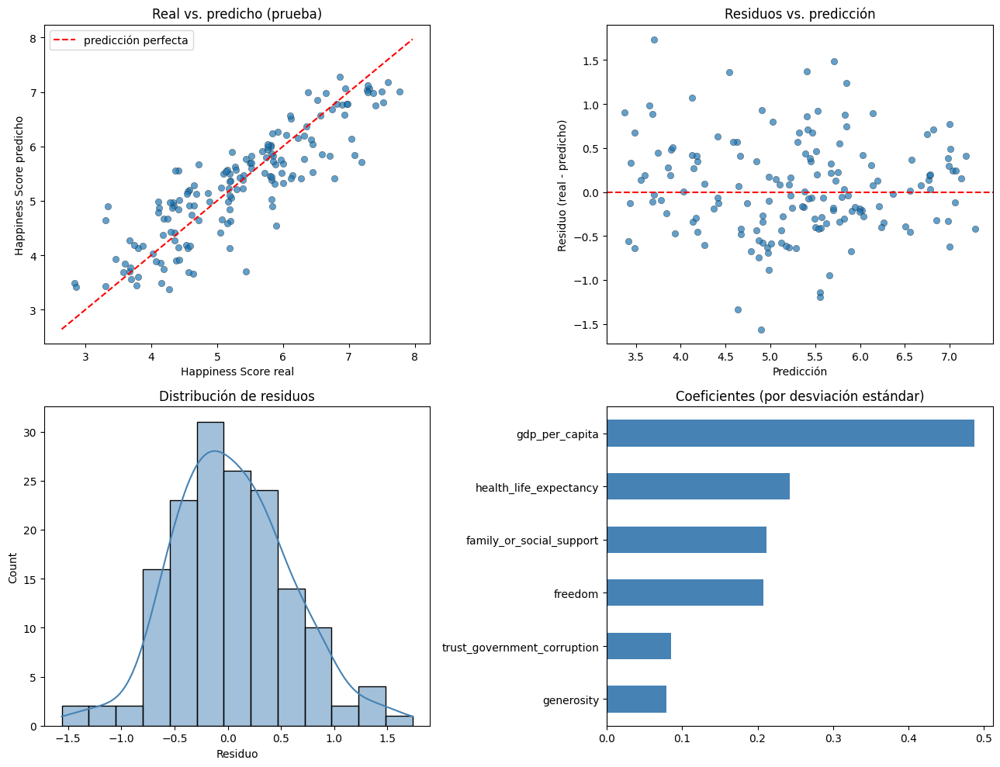

In [45]:
residuos = y_test.values - y_pred
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# 1. Real vs. predicho
ax = axes[0, 0]
ax.scatter(y_test, y_pred, alpha=0.7, edgecolor='k', linewidth=0.3)
lims = [min(y_test.min(), y_pred.min()) - 0.2, max(y_test.max(), y_pred.max()) + 0.2]
ax.plot(lims, lims, 'r--', label='predicción perfecta')
ax.set_xlabel('Happiness Score real')
ax.set_ylabel('Happiness Score predicho')
ax.set_title('Real vs. predicho (prueba)')
ax.legend()

# 2. Residuos vs. predichos
ax = axes[0, 1]
ax.scatter(y_pred, residuos, alpha=0.7, edgecolor='k', linewidth=0.3)
ax.axhline(0, color='red', linestyle='--')
ax.set_xlabel('Predicción')
ax.set_ylabel('Residuo (real - predicho)')
ax.set_title('Residuos vs. predicción')

# 3. Distribución de residuos
sns.histplot(residuos, kde=True, ax=axes[1, 0], color='steelblue')
axes[1, 0].set_title('Distribución de residuos')
axes[1, 0].set_xlabel('Residuo')

# 4. Coeficientes estandarizados
coefs = pd.Series(lr.coef_, index=FEATURES).sort_values()
coefs.plot.barh(ax=axes[1, 1], color='steelblue')
axes[1, 1].axvline(0, color='black', lw=0.8)
axes[1, 1].set_title('Coeficientes (por desviación estándar)')

plt.tight_layout()
plt.show()

###posibles mejoras

**Posibles mejoras:**

1. **Variables rezagadas:** incluir el score del año anterior del mismo país. Es información realista para predecir, aunque solo está disponible a partir de 2016.
2. **Regularización y búsqueda de hiperparámetros:** Ridge o Lasso, y ajuste de Random Forest con validación por país.
3. **Más años del World Happiness Report:** amplían la muestra y dan una validación temporal más sólida.
4. **Región como variable categórica:** disponible en 2015 y 2016; para los demás años requeriría una fuente externa.
5. **Revisión de datos:** los países con mayor error (tabla de la sección 1) pueden tener problemas de nombre o de valor.
6. **Incertidumbre:** reportar intervalos de confianza de las métricas, no solo valores puntuales.

## Configuración de conexiones

Reemplaza únicamente los marcadores `<...>` por tus datos del VPS. Las credenciales de Kafka siguen el mismo esquema de la celda de extracción (secretos de Colab).

In [ ]:
!pip install -q psycopg2-binary

# ===== CONFIGURACIÓN: reemplazar los marcadores <...> =====
PG_HOST = "<HOST_VPS>"          # IP o dominio del VPS, p. ej. 123.45.67.89
PG_PORT = 5432
PG_DATABASE = "<NOMBRE_BD>"
PG_USER = "<USUARIO>"
PG_PASSWORD = "<CONTRASEÑA>"

TOPIC_CAMBIOS = "etl.cambios_felicidad"   # cambios detectados en la tabla de PostgreSQL
TOPIC_MODELO = "etl.modelo_felicidad"     # modelo serializado (joblib en base64)
TABLA_PANEL = "felicidad_panel"           # tabla con el panel limpio (fuente de la detección de cambios)

# ===== Configuración base de Kafka (la misma conexión SASL_SSL del workshop) =====
from google.colab import userdata
import certifi
from confluent_kafka import Producer, Consumer

KAFKA_BASE = {
    "bootstrap.servers": "201.32.130.152:9092",
}
conf_productor = {**KAFKA_BASE, "acks": "all"}
print("Configuración cargada")

## Conexión a PostgreSQL (VPS) con SQLAlchemy

Se guardan tres tablas:

- **`felicidad_panel`**: panel limpio país-año usado por el modelo. Se carga con *upsert* (`INSERT ... ON CONFLICT`), así que los cambios hechos en la tabla no se pierden al volver a ejecutar.
- **`felicidad_predicciones`**: predicciones sobre el conjunto de prueba, con el error por registro.
- **`felicidad_metricas`**: métricas de cada modelo.

In [ ]:
from sqlalchemy import create_engine, URL, text

url_vps = URL.create(
    drivername="postgresql+psycopg2",
    username=PG_USER,
    password=PG_PASSWORD,
    host=PG_HOST,
    port=PG_PORT,
    database=PG_DATABASE,
)
engine_vps = create_engine(url_vps, pool_pre_ping=True)

with engine_vps.connect() as conn:
    version = conn.execute(text("SELECT version()")).scalar()
print("Conexión OK:", version[:60])

## Detección de cambios en la base de datos y publicación en Kafka

**Estrategia:** se guarda un *hash* SHA-256 por fila en la tabla de control `felicidad_control_hash`. En cada ejecución:

1. Se calcula el hash de cada fila actual de `felicidad_panel`.
2. Se compara con el hash guardado en la última ejecución.
3. Cada diferencia genera un evento: `INSERT` (fila nueva), `UPDATE` (fila modificada) o `DELETE` (fila eliminada).
4. Los eventos se publican en `etl.cambios_felicidad`. Solo si la entrega fue completa se actualiza la tabla de control.

**Orden de ejecución:** la detección corre **antes** y **después** de la carga del panel. Si corriera solo después, una fila borrada a mano se restauraría en la carga y su borrado nunca se publicaría.

> Esto es detección por comparación de snapshots (*polling*), adecuada para este workshop. En producción con alto volumen se usaría CDC (por ejemplo, Debezium sobre el WAL de PostgreSQL) o triggers de auditoría.

In [39]:
import hashlib
import json
from datetime import datetime, timezone

TABLA_CONTROL = "felicidad_control_hash"

def _a_tipo_json(o):
    return o.item() if hasattr(o, "item") else str(o)

def hash_fila(fila: dict) -> str:
    canonico = json.dumps(fila, sort_keys=True, ensure_ascii=False, default=_a_tipo_json)
    return hashlib.sha256(canonico.encode("utf-8")).hexdigest()

def leer_tabla_actual(engine):
    actual = pd.read_sql(text(f'SELECT * FROM "{TABLA_PANEL}"'), engine)
    actual = actual.astype(object).where(actual.notna(), None)
    actual["row_hash"] = [hash_fila({k: v for k, v in r.items()}) for r in actual.to_dict(orient="records")]
    return actual

def leer_control(engine):
    with engine.begin() as conn:
        conn.execute(text(f"""
            CREATE TABLE IF NOT EXISTS "{TABLA_CONTROL}" (
                record_id text PRIMARY KEY,
                row_hash text NOT NULL,
                actualizado_utc timestamptz NOT NULL
            )
        """))
    return pd.read_sql(text(f'SELECT record_id, row_hash FROM "{TABLA_CONTROL}"'), engine)

def detectar_cambios(engine):
    from sqlalchemy import inspect as sa_inspect
    if not sa_inspect(engine).has_table(TABLA_PANEL):
        return pd.DataFrame(columns=["record_id", "row_hash"]), []   # primera ejecución: aún no hay tabla
    actual = leer_tabla_actual(engine)
    control = leer_control(engine)

    comparado = actual[["record_id", "row_hash"]].merge(
        control, on="record_id", how="outer", suffixes=("_nuevo", "_previo"), indicator=True
    )
    eventos = []
    ts = datetime.now(timezone.utc).isoformat()
    por_id = actual.set_index("record_id")

    for _, r in comparado.iterrows():
        if r["_merge"] == "left_only":
            op, datos, h_prev, h_new = "INSERT", por_id.loc[r["record_id"]].drop("row_hash").to_dict(), None, r["row_hash_nuevo"]
        elif r["_merge"] == "right_only":
            op, datos, h_prev, h_new = "DELETE", None, r["row_hash_previo"], None
        elif r["row_hash_nuevo"] != r["row_hash_previo"]:
            op, datos, h_prev, h_new = "UPDATE", por_id.loc[r["record_id"]].drop("row_hash").to_dict(), r["row_hash_previo"], r["row_hash_nuevo"]
        else:
            continue
        eventos.append({
            "op": op,
            "tabla": TABLA_PANEL,
            "record_id": r["record_id"],
            "detectado_utc": ts,
            "hash_previo": h_prev,
            "hash_nuevo": h_new,
            "datos": datos,
        })
    return actual, eventos

def publicar_eventos(eventos, topic, conf=conf_productor):
    productor = Producer(conf)
    errores = []

    def reporte(err, msg):
        if err is not None:
            errores.append(str(err))

    for ev in eventos:
        productor.produce(
            topic,
            key=str(ev["record_id"]),
            value=json.dumps(ev, ensure_ascii=False, default=_a_tipo_json),
            callback=reporte,
        )
        productor.poll(0)

    pendientes = productor.flush(30)
    if pendientes or errores:
        raise RuntimeError(f"Entrega incompleta: pendientes={pendientes}, errores={errores[:3]}")
    return len(eventos)

def actualizar_control(engine, actual):
    ts = datetime.now(timezone.utc)
    staging = f"{TABLA_CONTROL}_staging"
    pd.DataFrame({
        "record_id": actual["record_id"],
        "row_hash": actual["row_hash"],
        "actualizado_utc": ts,
    }).to_sql(staging, engine, if_exists="replace", index=False)

    with engine.begin() as conn:
        conn.execute(text(f"""
            INSERT INTO "{TABLA_CONTROL}" (record_id, row_hash, actualizado_utc)
            SELECT record_id, row_hash, actualizado_utc FROM "{staging}"
            ON CONFLICT (record_id) DO UPDATE
              SET row_hash = EXCLUDED.row_hash, actualizado_utc = EXCLUDED.actualizado_utc
        """))
        conn.execute(text(f"""
            DELETE FROM "{TABLA_CONTROL}"
            WHERE record_id NOT IN (SELECT record_id FROM "{staging}")
        """))
        conn.execute(text(f'DROP TABLE "{staging}"'))

NameError: name 'conf_productor' is not defined

In [ ]:
def sincronizar_cambios(engine, etiqueta):
    actual_snapshot, eventos_cambio = detectar_cambios(engine)
    conteo_ops = pd.Series([e["op"] for e in eventos_cambio]).value_counts().to_dict() if eventos_cambio else {}
    print(f"[{etiqueta}] cambios detectados:", conteo_ops if conteo_ops else "ninguno")
    if eventos_cambio:
        publicados = publicar_eventos(eventos_cambio, TOPIC_CAMBIOS)
        actualizar_control(engine, actual_snapshot)
        print(f"[{etiqueta}] eventos publicados en '{TOPIC_CAMBIOS}': {publicados}; control actualizado")
    return eventos_cambio

# Paso 1: detectar cambios hechos en la tabla ANTES de volver a cargarla
sincronizar_cambios(engine_vps, "antes de cargar")

In [ ]:
# Prueba opcional: simular un cambio manual en la tabla para comprobar la detección.
# Cambia SIMULAR_CAMBIO a True, ejecuta esta celda y luego la anterior.
SIMULAR_CAMBIO = False

if SIMULAR_CAMBIO:
    with engine_vps.begin() as conn:
        conn.execute(text(f"""
            UPDATE "{TABLA_PANEL}"
            SET happiness_score = happiness_score + 0.1
            WHERE record_id = (SELECT record_id FROM "{TABLA_PANEL}" ORDER BY record_id LIMIT 1)
        """))
    print("Cambio simulado aplicado a una fila. Ejecuta la celda de sincronización de cambios.")

## Carga del panel y resultados en PostgreSQL

Ahora que la detección "antes de cargar" ya se ejecutó, se carga el panel limpio, se detectan los cambios que la carga haya dejado (sincronización "después de cargar") y se guardan predicciones y métricas.

In [ ]:
def guardar_upsert(df, engine, tabla, clave="record_id"):
    """Carga df en `tabla` con upsert por clave primaria. Crea la tabla si no existe."""
    tabla_stg = f"{tabla}_staging"
    df.to_sql(tabla_stg, engine, if_exists="replace", index=False)

    columnas = ", ".join(f'"{c}"' for c in df.columns)
    actualizar = ", ".join(f'"{c}" = EXCLUDED."{c}"' for c in df.columns if c != clave)

    with engine.begin() as conn:
        conn.execute(text(f'CREATE TABLE IF NOT EXISTS "{tabla}" AS SELECT * FROM "{tabla_stg}" WHERE false'))
        conn.execute(text(f"""
            DO $$
            BEGIN
              IF NOT EXISTS (SELECT 1 FROM pg_constraint WHERE conname = '{tabla}_pk') THEN
                ALTER TABLE "{tabla}" ADD CONSTRAINT {tabla}_pk PRIMARY KEY ({clave});
              END IF;
            END $$;
        """))
        conn.execute(text(f"""
            INSERT INTO "{tabla}" ({columnas})
            SELECT {columnas} FROM "{tabla_stg}"
            ON CONFLICT ({clave}) DO UPDATE SET {actualizar}
        """))
        conn.execute(text(f'DROP TABLE "{tabla_stg}"'))
    print(f"Tabla '{tabla}': {len(df)} filas procesadas")

guardar_upsert(feliz_modelo, engine_vps, TABLA_PANEL)

# Paso 2: publicar también los cambios que la carga del pipeline haya aplicado sobre la tabla
sincronizar_cambios(engine_vps, "después de cargar")

In [ ]:
# Predicciones y métricas: se reemplazan en cada ejecución (son resultados, no fuente de cambios)
predicciones_db = comparacion.reset_index(drop=True).copy()
predicciones_db.to_sql("felicidad_predicciones", engine_vps, if_exists="replace", index=False)

metricas_db = resultados.reset_index().copy()
metricas_db.to_sql("felicidad_metricas", engine_vps, if_exists="replace", index=False)
print("Tablas felicidad_predicciones y felicidad_metricas guardadas")

## Serialización del modelo y publicación en Kafka

El pipeline completo (preprocesamiento + regresión lineal) se serializa con `joblib`, igual que en `ml_basico`. Después se publica en `etl.modelo_felicidad` como base64, junto con su hash SHA-256 y sus métricas, para que cualquier consumidor pueda reconstruirlo y verificarlo.

El modelo lineal es pequeño (pocos KB), por lo que cabe en un mensaje de Kafka. El Random Forest pesa bastante más y no se publica por este medio.

In [38]:
import io
import base64
import joblib
import sklearn
from datetime import datetime, timezone

artefacto = {
    "pipeline": modelo_lineal,
    "features": FEATURES,
    "target": TARGET,
    "sklearn_version": sklearn.__version__,
}

buffer = io.BytesIO()
joblib.dump(artefacto, buffer)
bytes_modelo = buffer.getvalue()
sha_modelo = hashlib.sha256(bytes_modelo).hexdigest()

ruta_modelo = "felicidad_modelo_lineal.joblib"
joblib.dump(artefacto, ruta_modelo)

mensaje_modelo = {
    "modelo": "felicidad_regresion_lineal",
    "version_utc": datetime.now(timezone.utc).isoformat(),
    "sha256": sha_modelo,
    "tamano_bytes": len(bytes_modelo),
    "encoding": "base64",
    "contenido": base64.b64encode(bytes_modelo).decode("ascii"),
    "features": FEATURES,
    "sklearn_version": sklearn.__version__,
    "metricas_prueba": {k: float(v) for k, v in resultados.loc["Regresión lineal (aleatorio 80/20)"].items()},
}

assert len(mensaje_modelo["contenido"]) < 900_000, "El modelo supera el tamaño máximo recomendado del mensaje"

productor_modelo = Producer(conf_productor)
productor_modelo.produce(
    TOPIC_MODELO,
    key="felicidad_regresion_lineal",
    value=json.dumps(mensaje_modelo),
)
pendientes = productor_modelo.flush(30)
assert pendientes == 0, f"Quedaron {pendientes} mensajes sin entregar"

print(f"Modelo serializado: {len(bytes_modelo)} bytes | sha256={sha_modelo[:16]}...")
print(f"Publicado en '{TOPIC_MODELO}' y guardado en '{ruta_modelo}'")

NameError: name 'hashlib' is not defined

## Prueba del modelo después de consumirlo desde Kafka

Un consumidor independiente lee el último modelo publicado, verifica su hash, lo reconstruye y comprueba que sus predicciones coinciden con las del modelo original. Así se valida el contrato del artefacto antes de usarlo en otro proceso.

In [37]:
conf_consumidor = {
    **KAFKA_BASE,
    "group.id": conf_analisis["group.id"] + "-prueba-modelo",
    "auto.offset.reset": "earliest",
}

consumer_modelo = Consumer(conf_consumidor)
consumer_modelo.subscribe([TOPIC_MODELO])

ultimo_modelo = None
intentos = 0
try:
    while intentos < 20:
        msg = consumer_modelo.poll(timeout=1.0)
        if msg is None or msg.error():
            intentos += 1
            continue
        datos = json.loads(msg.value().decode("utf-8"))
        if datos.get("modelo") == "felicidad_regresion_lineal":
            ultimo_modelo = datos
        intentos = 0
finally:
    consumer_modelo.close()

assert ultimo_modelo is not None, "No se encontró ningún modelo en el topic"

bytes_recibidos = base64.b64decode(ultimo_modelo["contenido"])
assert hashlib.sha256(bytes_recibidos).hexdigest() == ultimo_modelo["sha256"], "El hash no coincide"

artefacto_recibido = joblib.load(io.BytesIO(bytes_recibidos))
pred_recibidas = artefacto_recibido["pipeline"].predict(X_test)

assert np.allclose(pred_recibidas, y_pred), "Las predicciones del modelo recibido no coinciden"
print("Modelo recibido, verificado y reconstruido.")
print("Predicciones idénticas a las del modelo original:", np.allclose(pred_recibidas, y_pred))

# Inferencia con un registro nuevo (como en ml_basico)
nuevo_registro = pd.DataFrame([{
    "gdp_per_capita": 1.2,
    "family_or_social_support": 1.3,
    "health_life_expectancy": 0.7,
    "freedom": 0.4,
    "trust_government_corruption": 0.15,
    "generosity": 0.1,
}])
print(f"Score estimado para el registro nuevo: {artefacto_recibido['pipeline'].predict(nuevo_registro)[0]:.3f}")

NameError: name 'KAFKA_BASE' is not defined